# Triple-Barrier Parameter Analysis

This notebook provides a workflow for analyzing and visualizing the choice of parameters for the Triple-Barrier labeling method.

The process is as follows:
1. **Load Execution Price Data**: Fetch the realistic bid/ask execution prices for a given market and date range.
2. **Calculate & Visualize Volatility**: Compute a rolling volatility measure from the historical data, which will be used to set dynamic barriers.
3. **Define Barriers & Generate Labels**: Use the calculated volatility to define the triple barriers and generate the resulting labels.
4. **Analyze Label Distribution**: Summarize and plot the distribution of outcomes (Win, Loss, Timeout) to understand the impact of the chosen parameters.

## Setup

Import libraries and define the core parameters for the analysis.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numba import jit

from qate.core.model import Market, ExchangeName, Symbol
from qate.env import sys_env
from qate.store.parquet_store import ParquetStore
from qate.util.dt_range import DtRange

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
sns.set_style("whitegrid")
%matplotlib inline

PARQUET_STORE_ROOT_DIR = sys_env.get_parquet_root_dir()
MARKET = Market(ExchangeName.GMO, Symbol.XRP_JPY)
EXECUTION_SIZE = "150"
TIMEZONE = 'Asia/Tokyo' # Define the local timezone for analysis

DATA_START_DATE = "2025-12-08"
DATA_END_DATE = "2025-12-12"

start_dt_aware = pd.Timestamp(f"{DATA_START_DATE} 00:00:00", tz=TIMEZONE)
end_dt_aware = pd.Timestamp(f"{DATA_END_DATE} 23:59:59", tz=TIMEZONE)
DATA_DT_RANGE = DtRange(start_dt_aware, end_dt_aware)

# ######
# Important AREA
#
# 1. Affect timeout percentage
# When RETURN_SHIFT_SEC == TIMEOUT_SEC 1.0 -> 50~60%, 2.0 -> 80~90%
# Really hard to explain ... maybe later ask AI to summarize.
BARRIER_MULTIPLIER = 1.5
#
# 2. Affect the imbalance of Win/Loss, longer -> more balanced but less predict power
RETURN_SHIFT_SEC = 180
# 3. See 1
TIMEOUT_SEC = RETURN_SHIFT_SEC

# Parameters for the new structural profitability filter
MAX_THEORETICAL_LOSS_RATE = 0.65 # Set a target max loss rate for filtering (e.g., 0.65 = 65%)

print(f"Setup complete. Analysis range: {start_dt_aware} to {end_dt_aware}")

Setup complete. Analysis range: 2025-12-08 00:00:00+09:00 to 2025-12-12 23:59:59+09:00


## 1. Load Execution Price Data

Load the execution price data which contains the realistic bid, ask, and mid prices for our chosen market and order size.

In [2]:
VOLATILITY_LOOKBACK_MINUTES = 60 # Use a 1-hour window for rolling volatility

vol_read_start_dt = start_dt_aware - pd.Timedelta(minutes=VOLATILITY_LOOKBACK_MINUTES)
load_range = DtRange(vol_read_start_dt, end_dt_aware)

print(f"Loading execution prices for {MARKET.id} (size: {EXECUTION_SIZE})...")
price_store = ParquetStore(PARQUET_STORE_ROOT_DIR).create_execution_price(MARKET, execution_size_str=EXECUTION_SIZE)
df = price_store.read(load_range)

if 'ts' in df.columns:
    # Ensure the 'ts' column is numeric, coercing errors to NaN
    df['ts'] = pd.to_numeric(df['ts'], errors='coerce')
    # Drop rows where 'ts' could not be converted to a numeric value
    df.dropna(subset=['ts'], inplace=True)

    # Convert to DatetimeIndex - use .dt accessor for Series timezone conversion
    df.index = pd.to_datetime(df['ts'], unit='s', utc=True).dt.tz_convert(TIMEZONE)
    df = df.drop(columns=['ts'])

if df.empty:
    print(f"Loaded {len(df)} data points.")
else:
    print(f"Loaded {len(df)} data points from {df.index.min()} to {df.index.max()}.")
df.head()

Loading execution prices for GMO:XRP_JPY (size: 150)...
Loaded 914340 data points from 2025-12-07 23:00:00.207000017+09:00 to 2025-12-12 23:59:58.721999884+09:00.


,bid,ask,mid,spread,spread_bps
ts,,,,,
2025-12-07 23:00:00.207000017+09:00,315.553000,315.728,315.640500,0.175000,5.544282
2025-12-07 23:00:00.711999893+09:00,315.553000,315.713,315.633000,0.160000,5.069178
2025-12-07 23:00:01.217000008+09:00,315.553133,315.718,315.635567,0.164867,5.223323
2025-12-07 23:00:01.723000050+09:00,315.553133,315.687,315.620067,0.133867,4.241386
2025-12-07 23:00:02.318000078+09:00,315.553133,315.687,315.620067,0.133867,4.241386


## 2. Calculate & Visualize Volatility

Here we implement **Methodology 1**: calculating dynamic barriers based on recent volatility. We'll compute the rolling standard deviation of 1-minute returns.

In [3]:
# --- Volatility Calculation ---
VOL_RESAMPLE_INTERVAL = "1s"
VOLATILITY_LOOKBACK_SEC = 3600
EMA_SPAN_SECONDS = 600  # since grid is 1s, 500 samples = 500 seconds

df = df.sort_index()

# 1s mid
mid_1s = df["mid"].resample(VOL_RESAMPLE_INTERVAL).last().ffill()

dt = pd.Timedelta(VOL_RESAMPLE_INTERVAL).total_seconds()
shift_periods = int(round(RETURN_SHIFT_SEC / dt))
lookback_periods = int(round(VOLATILITY_LOOKBACK_SEC / dt))

ret_1s = mid_1s.pct_change(periods=shift_periods)
vol_1s = ret_1s.rolling(window=lookback_periods, min_periods=1).std()

# 1s spread_pct (define spread_1s and mid_1s consistently)
spread_1s = df["spread"].resample(VOL_RESAMPLE_INTERVAL).last().ffill()
spread_pct_1s = spread_1s / mid_1s

volatility_ema_1s = vol_1s.ewm(span=EMA_SPAN_SECONDS, adjust=False).mean()
spread_pct_ema_1s = spread_pct_1s.ewm(span=EMA_SPAN_SECONDS, adjust=False).mean()

# If you need them back on tick index:
df["volatility_ema"] = volatility_ema_1s.reindex(df.index, method="ffill")
df["spread_pct_ema"] = spread_pct_ema_1s.reindex(df.index, method="ffill")

# Drop initial rows where EMA is not yet well-defined
df.dropna(inplace=True)

df[['mid', 'volatility_ema', 'spread_pct_ema']].head()

# # MEMO to check if the result is healthy
# df[["volatility_ema", "spread_pct_ema"]].corr()  # expecting big value 0.6~
# df[["volatility_ema", "spread_pct_ema"]].diff().corr() # expecting small value ~0.03


,mid,volatility_ema,spread_pct_ema
ts,,,
2025-12-07 23:03:01.134000063+09:00,315.5086,0.000029,0.00046
2025-12-07 23:03:01.512000083+09:00,315.5086,0.000029,0.00046
2025-12-07 23:03:02.161999941+09:00,315.5121,0.000029,0.00046
2025-12-07 23:03:02.667999983+09:00,315.5121,0.000029,0.00046
2025-12-07 23:03:03.174000025+09:00,315.5201,0.000029,0.00046


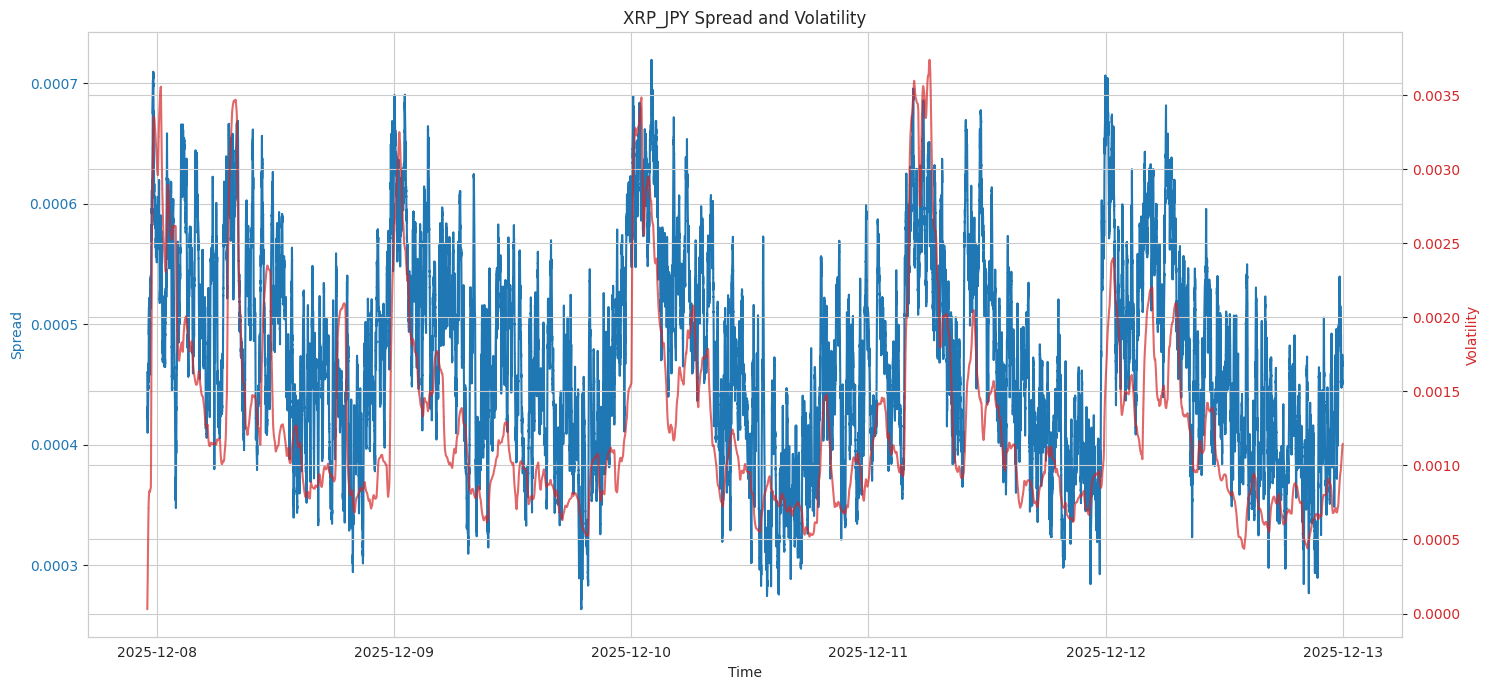

In [4]:
# Plot the mid-price and the calculated volatility
fig, ax1 = plt.subplots(figsize=(15, 7))

color = 'tab:blue'
ax1.set_xlabel('Time')
ax1.set_ylabel('Spread', color=color)
ax1.plot(df.index, df['spread_pct_ema'], color=color, label='Spread')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  # instantiate a second axes that shares the same x-axis
color = 'tab:red'
ax2.set_ylabel('Volatility', color=color)
ax2.plot(df.index, df['volatility_ema'], color=color, alpha=0.7, label='Volatility')
ax2.tick_params(axis='y', labelcolor=color)

plt.title(f'{MARKET.symbol.name} Spread and Volatility')
fig.tight_layout()
plt.show()

## 2.5 Pre-Labeling Filter: Structural Profitability Analysis

Before running the computationally expensive labeling process, we'll analyze the structural profitability of the market over the selected period. We use the 'Gambler's Ruin' heuristic `P(Loss) ≈ 0.5 + 0.5 * (s/v)` to estimate the probability of loss based on the current relationship between transaction costs (spread `s`) and volatility (`v`).

If the average theoretical loss rate is higher than our defined `MAX_THEORETICAL_LOSS_RATE`, it suggests the market conditions are structurally unfavorable for our strategy's parameters, and we should consider adjusting them before proceeding.

--- Structural Profitability Analysis ---
Average EMA Spread: 0.00048
Average EMA Volatility (absolute): 0.00193
Average Theoretical Loss Rate: 64.38%
Your Maximum Acceptable Rate: 65.00%


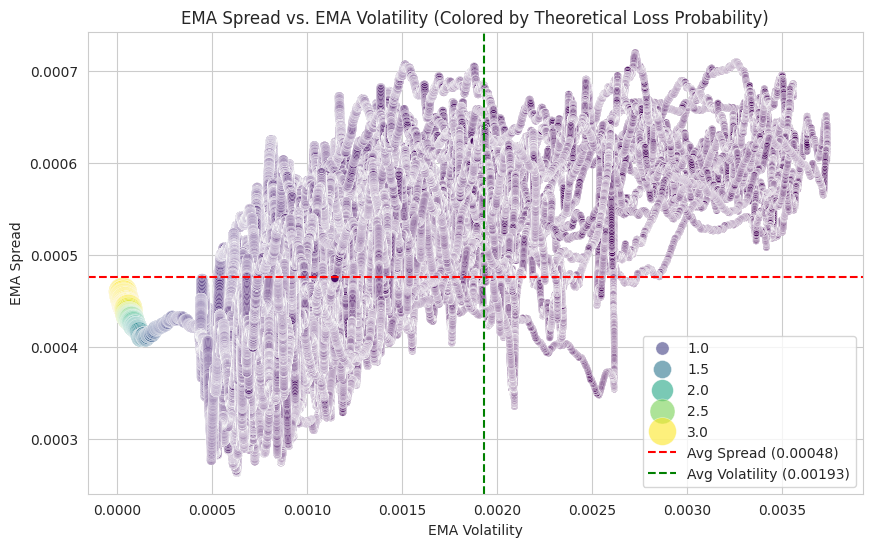


GO: The average theoretical loss rate is within your threshold. Proceeding to label generation.


,mid,theoretical_loss_p
count,913955.000000,913955.000000
mean,321.249047,0.643848
std,6.049331,0.056765
min,307.250000,0.545077
25%,316.579500,0.610764
50%,321.939000,0.642216
75%,325.078300,0.673193
max,341.613667,3.000000


In [5]:
# To make spread and volatility comparable, we need to express spread as a percentage of price
# s_pct = spread / mid_price
# v_pct = BARRIER_MULTIPLIER * volatility
# P(Loss) = 0.5 + 0.5 * (s_pct / v_pct)

# Use the smoothed EMA values for a more stable calculation

s_pct_ema = df['spread_pct_ema']
v_pct_ema = BARRIER_MULTIPLIER * df['volatility_ema']

# Calculate the theoretical probability of loss for each data point
# We cap the ratio at a high number to avoid extreme values from near-zero volatility
s_div_v = (s_pct_ema / v_pct_ema).clip(upper=5.0)
df['theoretical_loss_p'] = 0.5 + 0.5 * s_div_v

avg_loss_p = df['theoretical_loss_p'].mean()
avg_spread_ema = s_pct_ema.mean()
avg_volatility_ema = v_pct_ema.mean()

print("--- Structural Profitability Analysis ---")
print(f"Average EMA Spread: {avg_spread_ema:.5f}")
print(f"Average EMA Volatility (absolute): {avg_volatility_ema:.5f}")
print(f"Average Theoretical Loss Rate: {avg_loss_p:.2%}")
print(f"Your Maximum Acceptable Rate: {MAX_THEORETICAL_LOSS_RATE:.2%}")

# Plotting spread vs volatility
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['volatility_ema'], y=s_pct_ema, hue=df['theoretical_loss_p'], palette='viridis', size=df['theoretical_loss_p'], sizes=(20, 400), alpha=0.6)
plt.axhline(y=avg_spread_ema, color='r', linestyle='--', label=f'Avg Spread ({avg_spread_ema:.5f})')
plt.axvline(x=avg_volatility_ema, color='g', linestyle='--', label=f'Avg Volatility ({avg_volatility_ema:.5f})')
plt.title('EMA Spread vs. EMA Volatility (Colored by Theoretical Loss Probability)')
plt.xlabel('EMA Volatility')
plt.ylabel('EMA Spread')
plt.legend()
plt.grid(True)
plt.show()

if avg_loss_p > MAX_THEORETICAL_LOSS_RATE:
    print("\nSTOP: The average theoretical loss rate exceeds your threshold.")
    print("Recommendation: Adjust parameters (e.g., increase BARRIER_MULTIPLIER, or run on a different time period) and re-run the notebook from the 'Setup' cell.")
else:
    print("\nGO: The average theoretical loss rate is within your threshold. Proceeding to label generation.")
    
df[['mid', 'theoretical_loss_p']].describe()

## 3. Define Barriers & Generate Labels

Now we use the calculated `volatility` series to define our dynamic barriers and generate labels. For simplicity, we will only generate labels for a **long scenario**.

In [6]:
# Define the profit-take and stop-loss levels for each timestamp dynamically
df['pt_pct'] = BARRIER_MULTIPLIER * df['volatility_ema']
df['sl_pct'] = BARRIER_MULTIPLIER * df['volatility_ema']

print("Profit-take and Stop-loss levels (in %):")
(df[['pt_pct', 'sl_pct']] * 100).describe()

Profit-take and Stop-loss levels (in %):


,pt_pct,sl_pct
count,913955.000000,913955.000000
mean,0.193072,0.193072
std,0.100418,0.100418
min,0.004344,0.004344
25%,0.122631,0.122631
50%,0.159892,0.159892
75%,0.228010,0.228010
max,0.560754,0.560754


In [7]:
LABEL_RESAMPLE_INTERVAL = '100ms'  # Resample interval for label generation (reduces computation)

@jit(nopython=True)
def _compute_labels_numba(timestamps: np.ndarray, ask_prices: np.ndarray, 
                          high_prices: np.ndarray, low_prices: np.ndarray,
                          pt_pct: np.ndarray, sl_pct: np.ndarray, timeout_ns: int) -> tuple:
    """
    Numba-optimized inner loop for triple-barrier label computation.
    Checks against future high/low prices for more accurate barrier detection.
    
    Returns:
        labels: Array of labels (1=Win, -1=Loss, 0=Timeout)
        ambiguous_count: Number of cases where both barriers were hit in the same bar
    """
    n = len(timestamps)
    labels = np.zeros(n, dtype=np.int8)
    ambiguous_count = 0
    
    for i in range(n):
        entry_price = ask_prices[i]
        entry_ts = timestamps[i]
        timeout_ts = entry_ts + timeout_ns
        
        pt_level = pt_pct[i]
        sl_level = sl_pct[i]
        
        if np.isnan(entry_price) or np.isnan(pt_level) or np.isnan(sl_level):
            continue
        
        upper_barrier = entry_price * (1 + pt_level)
        lower_barrier = entry_price * (1 - sl_level)
        
        # Search future bars for a barrier hit
        for j in range(i + 1, n):
            if timestamps[j] > timeout_ts:
                break  # Timeout reached, label stays 0
            
            hit_upper = high_prices[j] >= upper_barrier
            hit_lower = low_prices[j] <= lower_barrier
            
            if hit_upper and hit_lower:
                # Both barriers hit in same bar - ambiguous case
                # Conservatively mark as Loss (avoid upward bias)
                labels[i] = -1
                ambiguous_count += 1
                break
            elif hit_upper:
                labels[i] = 1  # Profit Take
                break
            elif hit_lower:
                labels[i] = -1  # Stop Loss
                break
    
    return labels, ambiguous_count


def get_labels_with_dynamic_barriers(prices_df: pd.DataFrame, timeout_sec: int,
                                      resample_interval: str = '1s') -> tuple:
    """
    Computes triple-barrier labels using OHLC resampling for accuracy.
    
    Returns:
        DataFrame with labels, ambiguous_count
    """
    timeout_delta = pd.Timedelta(seconds=timeout_sec)

    aggregations = {
        'ask': 'first', 
        'bid': ['max', 'min'],
        'pt_pct': 'first',
        'sl_pct': 'first'
    }
    
    df_resampled = prices_df.resample(resample_interval).agg(aggregations).dropna()
    df_resampled.columns = ['_'.join(col).strip() for col in df_resampled.columns.values]
    
    n = len(df_resampled)
    if n == 0:
        return pd.DataFrame({'label': []}, index=pd.DatetimeIndex([])), 0
    
    # Convert to numpy arrays for numba
    timestamps = df_resampled.index.values.astype('datetime64[ns]').astype(np.int64)
    ask_prices = df_resampled['ask_first'].values.astype(np.float64)
    high_prices = df_resampled['bid_max'].values.astype(np.float64)
    low_prices = df_resampled['bid_min'].values.astype(np.float64)
    pt_pct = df_resampled['pt_pct_first'].values.astype(np.float64)
    sl_pct = df_resampled['sl_pct_first'].values.astype(np.float64)
    timeout_ns = int(timeout_delta.total_seconds() * 1e9)
    
    # Run numba-optimized computation
    labels, ambiguous_count = _compute_labels_numba(
        timestamps, ask_prices, high_prices, low_prices, pt_pct, sl_pct, timeout_ns
    )
    
    return pd.DataFrame({'label': labels}, index=df_resampled.index), ambiguous_count


# Generate the labels
print(f"Generating labels with {TIMEOUT_SEC}s timeout, resampled to {LABEL_RESAMPLE_INTERVAL}...")
print(f"Original data points: {len(df)}")
labels_df, ambiguous_count = get_labels_with_dynamic_barriers(df, TIMEOUT_SEC, resample_interval=LABEL_RESAMPLE_INTERVAL)
print(f"Resampled data points: {len(labels_df)}")
print(f"Ambiguous cases (both barriers hit in same bar): {ambiguous_count} ({ambiguous_count/len(labels_df)*100:.2f}%)")

# Join labels back - reindex to original df's index with forward fill
df['label'] = labels_df['label'].reindex(df.index, method='ffill')
print("Label generation complete.")
df[['mid', 'volatility_ema', 'pt_pct', 'sl_pct', 'label']].head()

Generating labels with 180s timeout, resampled to 100ms...
Original data points: 913955
Resampled data points: 904173
Ambiguous cases (both barriers hit in same bar): 0 (0.00%)
Label generation complete.


,mid,volatility_ema,pt_pct,sl_pct,label
ts,,,,,
2025-12-07 23:03:01.134000063+09:00,315.5086,0.000029,0.000043,0.000043,-1
2025-12-07 23:03:01.512000083+09:00,315.5086,0.000029,0.000043,0.000043,-1
2025-12-07 23:03:02.161999941+09:00,315.5121,0.000029,0.000043,0.000043,-1
2025-12-07 23:03:02.667999983+09:00,315.5121,0.000029,0.000043,0.000043,-1
2025-12-07 23:03:03.174000025+09:00,315.5201,0.000029,0.000044,0.000044,-1


## 4. Analyze Label Distribution

Finally, we analyze the outcomes. How many of our potential trades resulted in a win, a loss, or a timeout? This is critical for understanding if the barrier parameters are well-chosen. If 99% of labels are timeouts, the barriers might be too wide or the timeout too short.

Label Distribution Summary (excluding last 180s of data):
Total samples analyzed: 903,796
                       count  percentage
label                                   
Loss (SL = 1.5x Vol)  236765       26.20
Timeout (180s)        599130       66.29
Win (PT = 1.5x Vol)    67901        7.51


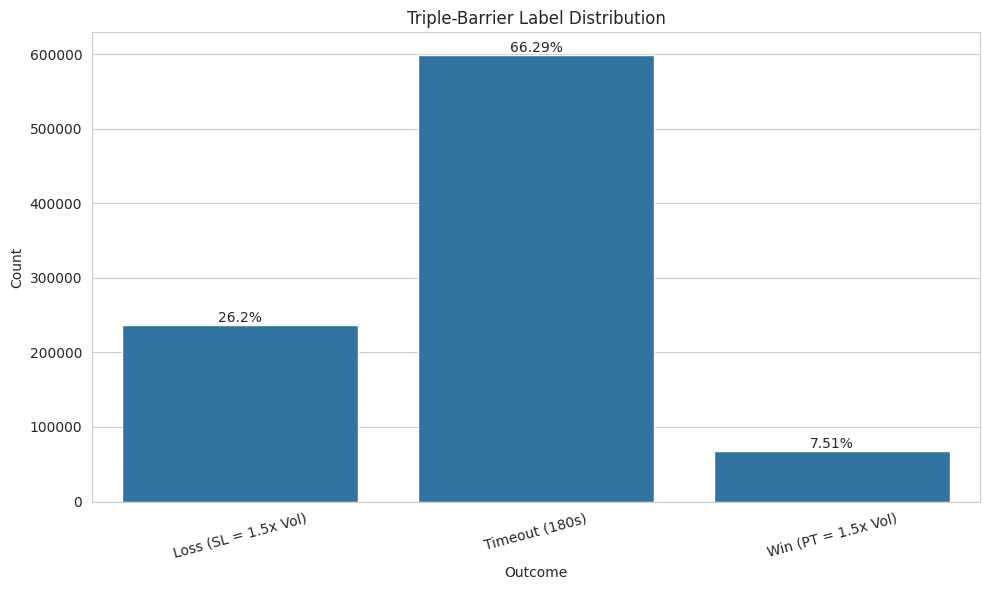

In [8]:
# Exclude the last TIMEOUT_SEC of data (edge effect - no future data to check barriers)
cutoff_time = labels_df.index.max() - pd.Timedelta(seconds=TIMEOUT_SEC)
labels_valid = labels_df.loc[labels_df.index <= cutoff_time, 'label'].dropna()

label_counts = labels_valid.value_counts().sort_index()

# Create a mapping for human-readable labels
label_map = {
    1: f'Win (PT = {BARRIER_MULTIPLIER}x Vol)',
    -1: f'Loss (SL = {BARRIER_MULTIPLIER}x Vol)',
    0: f'Timeout ({TIMEOUT_SEC}s)'
}
label_counts.rename(index=label_map, inplace=True)

print(f"Label Distribution Summary (excluding last {TIMEOUT_SEC}s of data):")
print(f"Total samples analyzed: {len(labels_valid):,}")
summary_df = pd.DataFrame({
    'count': label_counts,
    'percentage': (label_counts / label_counts.sum() * 100).round(2)
})
print(summary_df)

# Plot the distribution
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=summary_df.index, y=summary_df['count'])
ax.set_title('Triple-Barrier Label Distribution')
ax.set_ylabel('Count')
ax.set_xlabel('Outcome')

# Add percentage labels to the bars
for i, p in enumerate(ax.patches):
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2.,
            height + 0.1,
            f"{summary_df['percentage'].iloc[i]}%",
            ha="center", va="bottom")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Memo of conversation with AI

### What affects the win/loss rate

Setup
- Resample interval of volatility calculation = Tvol
- Timeout = Tvol
- Target profit = P

Factors
- Volatility = V
- Spread = S

```
Loss rate = 0.5 + 0.5 * (S/V)
```

The "Gambler's Ruin" Analogy

Imagine a particle starting at position 0 on a number line. At each step, it moves +1 or -1 with a 50% chance (a "symmetric random walk"). The game stops if the particle hits one of two walls:
* An upper "win" wall at position +a.
* A lower "loss" wall at position -b.

The well-known solution for the probability of hitting the lower wall at -b before hitting the upper wall at +a is:

P(Loss) = a / (a + b)

Applying it to Our Trading Model

Now, let's map our trading variables to this model:
* The "particle" is the true underlying price of the asset.
* a is the distance the price needs to travel up to trigger a win. As we established, this is v + s (it has to cover the barrier distance v plus the spread s).
* b is the distance the price needs to travel down to trigger a loss. This is v - s.

Now, we just plug our financial model's distances into the classic Gambler's Ruin formula:

1. Start with the formula:
P(Loss) = a / (a + b)

2. Substitute our distances:
P(Loss) = (v + s) / ( (v + s) + (v - s) )

3. Simplify the denominator:
P(Loss) = (v + s) / (2v)

4. Split the fraction:
P(Loss) = v/(2v) + s/(2v)

5. And you get the final expression:
P(Loss) = 0.5 + 0.5 * (s/v)

### The process/purpose to execute the notebook

Summary: A Dynamic Labeling Strategy Based on Structural Profitability

The proposed methodology is to evolve from a simple, static labeling process to a dynamic, regime-aware filtering system. The core principle is to only generate labels for entry points that have a favorable
structural probability of success, based on real-time market conditions.

This is achieved through the following steps:

1. Modeling Market Conditions: We will continuously track two key metrics:
* Transaction Cost: Represented by an Exponential Moving Average (EMA) of the bid-ask spread (s).
* Market Volatility: Represented by an EMA of the price volatility (v), calculated over a time horizon appropriate for the strategy.

2. Dynamic Entry Filtering: At each moment, we will use the formula derived from the "Gambler's Ruin" problem—`P(Loss) ≈ 0.5 + 0.5 * (s/v)`—to calculate the theoretical probability of a loss for a potential
trade initiated under the current market conditions.

3. Applying a Quality Threshold: We will define a hyperparameter, `X`, which represents the maximum acceptable theoretical loss rate. A triple-barrier label will only be generated if the calculated P(Loss) is
less than X. This acts as a filter to discard trades initiated during unfavorable regimes (e.g., high-spread/low-volatility periods).

4. Time Horizon Alignment: The volatility measurement window must be carefully tuned to align with the desired trading frequency (e.g., shorter windows for scalping strategies) to ensure the s/v ratio is
meaningful.

In essence, you are proposing to build a meta-model that pre-qualifies trades. It uses a simple, powerful heuristic to decide when the game is even worth playing, ensuring that the final labels are generated only
for high-quality opportunities. This is a superb approach that should dramatically increase the robustness and value of the resulting labels.
